# Derivable Judgement: A Statistical Decision-Making Model

## Project Objective
To apply inferential statistics and hypothesis testing to synthetic health data
to investigate relationships between lifestyle factors and health conditions.

## Dataset
50,000 synthetic health records containing 15 columns.

## Tools and Technologies
- Python
- Jupyter Notebook
- Pandas
- NumPy
- SciPy
- Matplotlib
- Seaborn
- Statsmodels

In [9]:
# Import required libraries

import pandas as pd
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels

print("All libraries imported successfully!")

print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("SciPy Version:", scipy.__version__)
print("Matplotlib Version:", matplotlib.__version__)
print("Seaborn Version:", sns.__version__)
print("Statsmodels Version:", statsmodels.__version__)

All libraries imported successfully!
Pandas Version: 2.3.3
NumPy Version: 2.3.5
SciPy Version: 1.16.3
Matplotlib Version: 3.10.6
Seaborn Version: 0.13.2
Statsmodels Version: 0.14.5


In [10]:
# Load the dataset

df = pd.read_csv("derivable_judgement_health_dataset.csv")

print("Dataset loaded successfully!")
print("-" * 50)

print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])

print("-" * 50)

print("\nFirst 5 Records:")
display(df.head())

Dataset loaded successfully!
--------------------------------------------------
Total Records: 50000
Total Columns: 15
--------------------------------------------------

First 5 Records:


,record_id,age_group,age,weight,gender,region,smoking_status,exercise_frequency,bmi,blood_pressure,diabetes,hypertension,cholesterol_level,glucose_level,visit_date
0,REC000001,18-25,24,69,Female,North,Former Smoker,Rarely,23.7,131.1,False,False,134.5,55.0,31-03-2025
1,REC000002,60+,70,84,Other,West,Former Smoker,Rarely,29.2,154.8,False,False,185.2,119.0,06-03-2023
2,REC000003,60+,62,56,Female,North,Non-Smoker,Weekly,21.3,144.3,False,False,207.8,73.8,26-10-2026
3,REC000004,46-60,47,81,Male,South,Non-Smoker,Rarely,25.9,113.1,False,True,178.6,74.4,28-07-2024
4,REC000005,46-60,47,94,Female,East,Non-Smoker,Rarely,33.8,144.5,False,False,217.0,78.5,24-04-2026


In [11]:
# Display dataset information

print("Dataset Information")
print("=" * 50)

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types and Non-Null Counts:")
df.info()

Dataset Information

Dataset Shape:
(50000, 15)

Column Names:
['record_id', 'age_group', 'age', 'weight', 'gender', 'region', 'smoking_status', 'exercise_frequency', 'bmi', 'blood_pressure', 'diabetes', 'hypertension', 'cholesterol_level', 'glucose_level', 'visit_date']

Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   record_id           50000 non-null  object 
 1   age_group           50000 non-null  object 
 2   age                 50000 non-null  int64  
 3   weight              50000 non-null  int64  
 4   gender              50000 non-null  object 
 5   region              50000 non-null  object 
 6   smoking_status      50000 non-null  object 
 7   exercise_frequency  50000 non-null  object 
 8   bmi                 50000 non-null  float64
 9   blood_pressure      50000 non-null  float6

In [12]:
# Check missing values

print("Missing Values in Each Column:")
display(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Check duplicate records

print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())

# Check duplicate record IDs

print("\nDuplicate Record IDs:")
print(df["record_id"].duplicated().sum())

Missing Values in Each Column:


record_id             0
age_group             0
age                   0
weight                0
gender                0
region                0
smoking_status        0
exercise_frequency    0
bmi                   0
blood_pressure        0
diabetes              0
hypertension          0
cholesterol_level     0
glucose_level         0
visit_date            0
dtype: int64


Total Missing Values:
0

Total Duplicate Rows:
0

Duplicate Record IDs:
0


# Data Cleaning & Exploratory Data Analysis (EDA)

In [13]:
# Check data types of all columns

print("DATA TYPES OF ALL COLUMNS")
print("=" * 50)

display(df.dtypes)

DATA TYPES OF ALL COLUMNS


record_id              object
age_group              object
age                     int64
weight                  int64
gender                 object
region                 object
smoking_status         object
exercise_frequency     object
bmi                   float64
blood_pressure        float64
diabetes                 bool
hypertension             bool
cholesterol_level     float64
glucose_level         float64
visit_date             object
dtype: object

In [14]:
# Descriptive statistics for numerical columns

print("DESCRIPTIVE STATISTICS")
print("=" * 60)

display(df.describe().round(2))

DESCRIPTIVE STATISTICS


,age,weight,bmi,blood_pressure,cholesterol_level,glucose_level
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,51.46,71.43,25.22,126.63,183.04,97.82
std,19.64,14.51,4.24,14.72,30.63,20.42
min,18.00,38.00,10.90,80.00,90.00,55.00
25%,34.00,61.00,22.30,116.60,162.20,83.50
50%,52.00,71.00,25.20,126.70,183.20,97.60
75%,68.00,81.00,28.10,136.70,203.80,111.80
max,85.00,150.00,42.90,183.50,320.20,180.00


In [15]:
# Summary of categorical columns

categorical_columns = [
    "age_group",
    "gender",
    "region",
    "smoking_status",
    "exercise_frequency"
]

for column in categorical_columns:
    print(f"\nDistribution of {column}:")
    display(df[column].value_counts().to_frame("Count"))


Distribution of age_group:


,Count
age_group,
60+,18392
46-60,11013
26-35,7380
36-45,7310
18-25,5905



Distribution of gender:


,Count
gender,
Female,24670
Male,24342
Other,988



Distribution of region:


,Count
region,
East,12625
South,12497
West,12468
North,12410



Distribution of smoking_status:


,Count
smoking_status,
Non-Smoker,30950
Smoker,11021
Former Smoker,8029



Distribution of exercise_frequency:


,Count
exercise_frequency,
Weekly,19084
Rarely,13811
Daily,10062
Never,7043


In [16]:
# Disease distribution

print("DISEASE DISTRIBUTION")
print("=" * 50)

print("\nDiabetes:")
display(df["diabetes"].value_counts().to_frame("Count"))

print("\nHypertension:")
display(df["hypertension"].value_counts().to_frame("Count"))

print("\nDiabetes Percentage:")
print(round(df["diabetes"].mean() * 100, 2), "%")

print("\nHypertension Percentage:")
print(round(df["hypertension"].mean() * 100, 2), "%")

DISEASE DISTRIBUTION

Diabetes:


,Count
diabetes,
False,45892
True,4108



Hypertension:


,Count
hypertension,
False,42543
True,7457



Diabetes Percentage:
8.22 %

Hypertension Percentage:
14.91 %


# EDA Charts

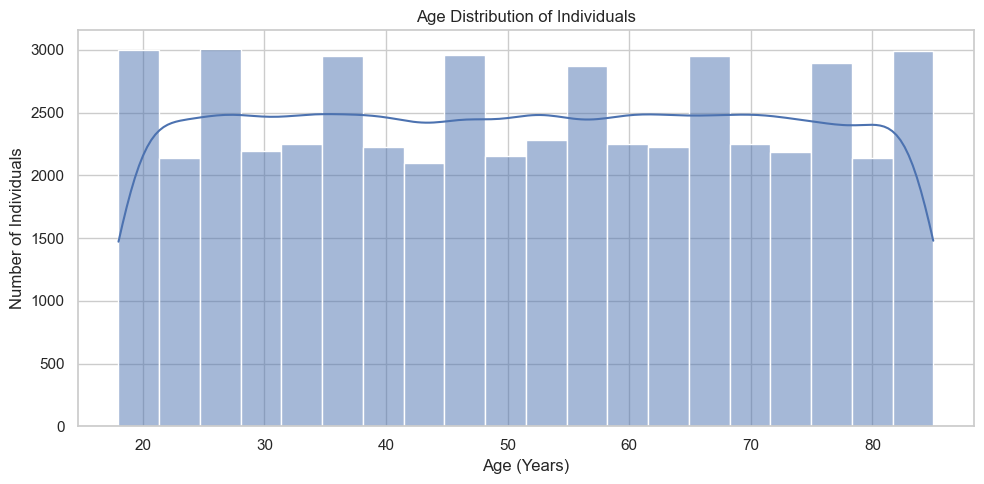

In [20]:
#Age Distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Age Distribution of Individuals")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Individuals")

plt.tight_layout()
plt.show()

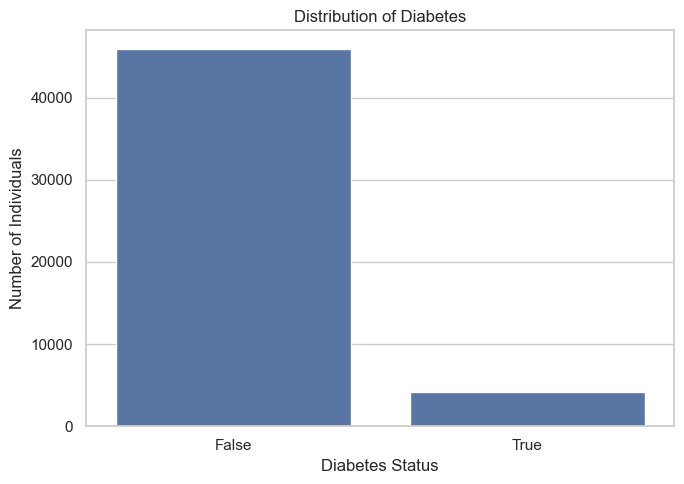

In [23]:
#Diabetes Distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="diabetes")

plt.title("Distribution of Diabetes")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Individuals")

plt.tight_layout()
plt.show()

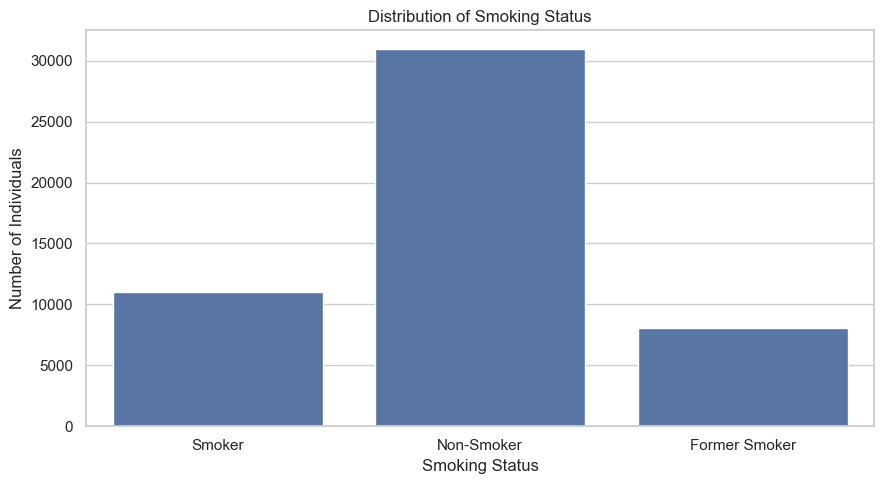

In [24]:
#Smoking Status Distribution
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="smoking_status",
    order=["Smoker", "Non-Smoker", "Former Smoker"]
)

plt.title("Distribution of Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Number of Individuals")

plt.tight_layout()
plt.show()

## Confidence Interval

A confidence interval is a range of values used to estimate an unknown population parameter based on sample data.

A 95% confidence interval indicates the reliability of the estimation procedure. Across repeated random samples, approximately 95% of intervals constructed using this method would contain the true population parameter, assuming the method's conditions are satisfied.

In this project, we will calculate 95% confidence intervals for numerical health variables such as age, weight, BMI, blood pressure, cholesterol level, and glucose level.

In [25]:
# STEP 5: Calculate 95% Confidence Intervals

from scipy import stats
import numpy as np
import pandas as pd

# Numerical columns selected for analysis
numerical_columns = [
    "age",
    "weight",
    "bmi",
    "blood_pressure",
    "cholesterol_level",
    "glucose_level"
]

confidence_level = 0.95
alpha = 1 - confidence_level

results = []

for column in numerical_columns:

    data = df[column].dropna()

    sample_size = len(data)
    sample_mean = data.mean()
    standard_error = stats.sem(data)

    # Calculate critical t-value
    critical_value = stats.t.ppf(
        1 - alpha / 2,
        df=sample_size - 1
    )

    # Calculate confidence interval
    margin_of_error = critical_value * standard_error

    lower_limit = sample_mean - margin_of_error
    upper_limit = sample_mean + margin_of_error

    results.append({
        "Variable": column,
        "Sample Size": sample_size,
        "Sample Mean": sample_mean,
        "Standard Error": standard_error,
        "Critical t-value": critical_value,
        "95% CI Lower": lower_limit,
        "95% CI Upper": upper_limit
    })

ci_results = pd.DataFrame(results)

print("95% CONFIDENCE INTERVAL RESULTS")
print("=" * 90)

display(ci_results.round(4))

95% CONFIDENCE INTERVAL RESULTS


,Variable,Sample Size,Sample Mean,Standard Error,Critical t-value,95% CI Lower,95% CI Upper
0,age,50000,51.4617,0.0879,1.96,51.2895,51.6339
1,weight,50000,71.4261,0.0649,1.96,71.2989,71.5532
2,bmi,50000,25.2178,0.0189,1.96,25.1806,25.2549
3,blood_pressure,50000,126.6343,0.0658,1.96,126.5053,126.7633
4,cholesterol_level,50000,183.0436,0.1370,1.96,182.7752,183.3121
5,glucose_level,50000,97.8211,0.0913,1.96,97.6421,98.0001


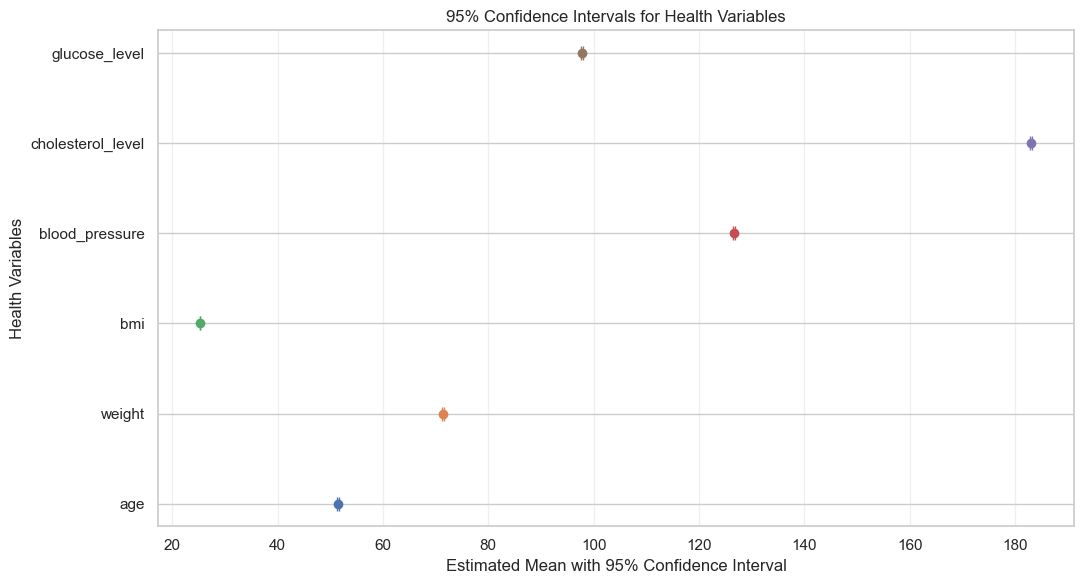

In [26]:
# Visualize 95% Confidence Intervals

plt.figure(figsize=(11, 6))

for index, row in ci_results.iterrows():

    mean = row["Sample Mean"]

    lower_error = mean - row["95% CI Lower"]
    upper_error = row["95% CI Upper"] - mean

    plt.errorbar(
        x=mean,
        y=row["Variable"],
        xerr=[[lower_error], [upper_error]],
        fmt="o",
        capsize=5
    )

plt.title("95% Confidence Intervals for Health Variables")
plt.xlabel("Estimated Mean with 95% Confidence Interval")
plt.ylabel("Health Variables")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

##  Chi-Square Test of Independence

The Chi-Square Test of Independence is used to determine whether a statistically significant association exists between two categorical variables.

In this project, the test will examine whether smoking status is associated with diabetes status.

- **Null Hypothesis (H₀):** Smoking status and diabetes are independent.
- **Alternative Hypothesis (H₁):** Smoking status and diabetes are associated.
- **Significance Level (α):** 0.05

If the p-value is less than 0.05, we reject the null hypothesis. Otherwise, we fail to reject the null hypothesis.

In [28]:
# STEP 7: Smoking Status vs Diabetes

import pandas as pd
from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(
    df["smoking_status"],
    df["diabetes"]
)

print("CONTINGENCY TABLE: SMOKING STATUS VS DIABETES")
print("=" * 55)

display(contingency_table)

CONTINGENCY TABLE: SMOKING STATUS VS DIABETES


diabetes,False,True
smoking_status,,
Former Smoker,7390,639
Non-Smoker,28575,2375
Smoker,9927,1094


In [29]:
# Perform Chi-Square Test of Independence

chi2_statistic, p_value, degrees_of_freedom, expected_frequencies = (
    chi2_contingency(contingency_table)
)

alpha = 0.05

# Calculate the critical value
critical_value = __import__("scipy").stats.chi2.ppf(
    1 - alpha,
    degrees_of_freedom
)

print("CHI-SQUARE TEST RESULTS")
print("=" * 50)

print(f"Chi-Square Statistic : {chi2_statistic:.4f}")
print(f"Degrees of Freedom   : {degrees_of_freedom}")
print(f"Critical Value       : {critical_value:.4f}")
print(f"P-value              : {p_value:.6f}")
print(f"Significance Level   : {alpha}")

print("\nEXPECTED FREQUENCIES:")
display(
    pd.DataFrame(
        expected_frequencies,
        index=contingency_table.index,
        columns=contingency_table.columns
    ).round(2)
)

print("\nSTATISTICAL DECISION")
print("=" * 50)

if p_value < alpha:
    print("Reject H0")
    print(
        "There is statistically significant evidence of an association "
        "between smoking status and diabetes."
    )
else:
    print("Fail to reject H0")
    print(
        "There is insufficient statistical evidence of an association "
        "between smoking status and diabetes."
    )

if (expected_frequencies < 5).any():
    print("\nWarning: Some expected cell frequencies are below 5.")
    print("Review the Chi-square test assumptions.")
else:
    print("\nAll expected cell frequencies are at least 5.")

CHI-SQUARE TEST RESULTS
Chi-Square Statistic : 55.5372
Degrees of Freedom   : 2
Critical Value       : 5.9915
P-value              : 0.000000
Significance Level   : 0.05

EXPECTED FREQUENCIES:


diabetes,False,True
smoking_status,,
Former Smoker,7369.34,659.66
Non-Smoker,28407.15,2542.85
Smoker,10115.51,905.49



STATISTICAL DECISION
Reject H0
There is statistically significant evidence of an association between smoking status and diabetes.

All expected cell frequencies are at least 5.


In [30]:
# Calculate diabetes prevalence by smoking status

diabetes_prevalence = (
    df.groupby("smoking_status", observed=True)["diabetes"]
    .mean()
    .mul(100)
    .reset_index(name="Diabetes Prevalence (%)")
)

print("DIABETES PREVALENCE BY SMOKING STATUS")
print("=" * 50)

display(diabetes_prevalence.round(2))

DIABETES PREVALENCE BY SMOKING STATUS


,smoking_status,Diabetes Prevalence (%)
0,Former Smoker,7.96
1,Non-Smoker,7.67
2,Smoker,9.93


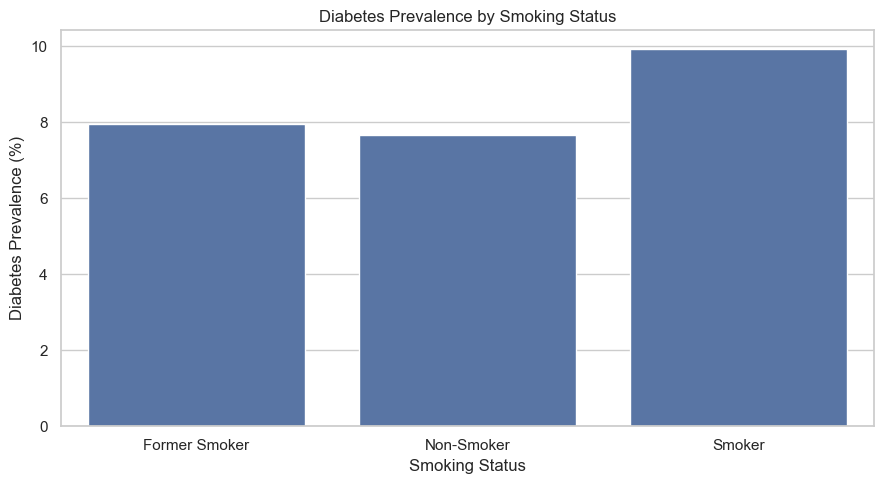

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=diabetes_prevalence,
    x="smoking_status",
    y="Diabetes Prevalence (%)"
)

plt.title("Diabetes Prevalence by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Diabetes Prevalence (%)")

plt.tight_layout()
plt.show()

## Pearson Correlation Test

Pearson correlation measures the strength and direction of the linear relationship between two numerical variables. Its correlation coefficient ranges from -1 to +1.

In this project, we will examine the relationship between Age and BMI.

- **Null Hypothesis (H₀):** There is no linear correlation between Age and BMI in the population (ρ = 0).
- **Alternative Hypothesis (H₁):** There is a linear correlation between Age and BMI in the population (ρ ≠ 0).
- **Significance Level (α):** 0.05

If the p-value is less than 0.05, we reject H₀. Otherwise, we fail to reject H₀.

In [33]:
# STEP 8: Pearson Correlation Test - Age vs BMI

from scipy.stats import pearsonr

# Select numerical variables
age_data = df["age"]
bmi_data = df["bmi"]

# Perform Pearson correlation test
correlation_coefficient, p_value = pearsonr(
    age_data,
    bmi_data
)

alpha = 0.05

print("PEARSON CORRELATION TEST: AGE VS BMI")
print("=" * 55)

print(f"Sample Size: {len(df)}")
print(f"Correlation Coefficient (r): {correlation_coefficient:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Significance Level (alpha): {alpha}")

print("\nSTATISTICAL DECISION")
print("=" * 55)

if p_value < alpha:
    print("Reject H0")
    print("There is statistically significant evidence of a linear correlation.")
else:
    print("Fail to reject H0")
    print("There is insufficient evidence of a linear correlation.")

print("\nCORRELATION INTERPRETATION")
print("=" * 55)

if correlation_coefficient > 0:
    print("Direction: Positive correlation")
elif correlation_coefficient < 0:
    print("Direction: Negative correlation")
else:
    print("Direction: No linear correlation")

strength = abs(correlation_coefficient)

if strength < 0.10:
    print("Strength: Negligible linear correlation")
elif strength < 0.30:
    print("Strength: Weak linear correlation")
elif strength < 0.50:
    print("Strength: Moderate linear correlation")
else:
    print("Strength: Strong linear correlation")

PEARSON CORRELATION TEST: AGE VS BMI
Sample Size: 50000
Correlation Coefficient (r): 0.1665
P-value: 0.000000
Significance Level (alpha): 0.05

STATISTICAL DECISION
Reject H0
There is statistically significant evidence of a linear correlation.

CORRELATION INTERPRETATION
Direction: Positive correlation
Strength: Weak linear correlation


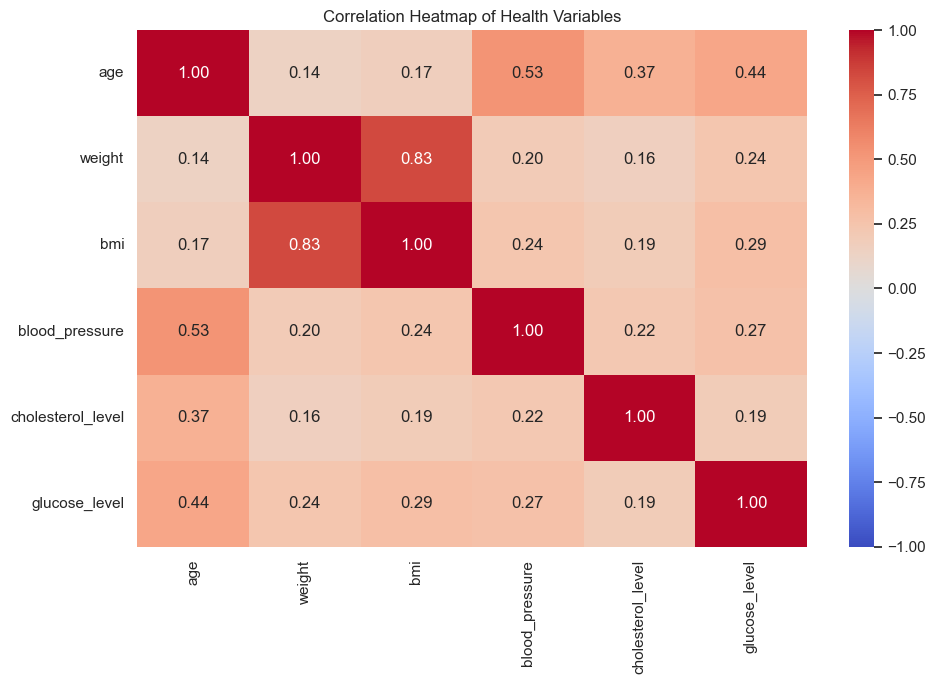

In [34]:
# Correlation matrix for numerical variables

numerical_columns = [
    "age",
    "weight",
    "bmi",
    "blood_pressure",
    "cholesterol_level",
    "glucose_level"
]

correlation_matrix = df[numerical_columns].corr(method="pearson")

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Health Variables")
plt.tight_layout()
plt.show()

## Independent Two-Sample T-Test

An independent two-sample t-test is used to compare the means of two independent groups.

In this project, we will compare the average blood pressure of smokers and non-smokers using Welch's t-test, which does not require equal population variances.

**Null Hypothesis (H₀):** The population mean blood pressure of smokers and non-smokers is equal.

**Alternative Hypothesis (H₁):** The population mean blood pressure of smokers and non-smokers is different.

**Significance Level (α):** 0.05

If the p-value is less than 0.05, we reject H₀. Otherwise, we fail to reject H₀.

In [36]:
# STEP 9: Welch's Independent Two-Sample T-Test
# Compare blood pressure of smokers and non-smokers

from scipy import stats
import numpy as np
import pandas as pd

# Separate the two independent groups
smokers = df.loc[
    df["smoking_status"] == "Smoker",
    "blood_pressure"
].dropna()

non_smokers = df.loc[
    df["smoking_status"] == "Non-Smoker",
    "blood_pressure"
].dropna()

# Significance level
alpha = 0.05

# Perform Welch's t-test
t_statistic, p_value = stats.ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="two-sided"
)

# Calculate degrees of freedom using Welch-Satterthwaite formula
n1 = len(smokers)
n2 = len(non_smokers)

s1_squared = smokers.var(ddof=1)
s2_squared = non_smokers.var(ddof=1)

numerator = (s1_squared / n1 + s2_squared / n2) ** 2

denominator = (
    (s1_squared / n1) ** 2 / (n1 - 1)
    + (s2_squared / n2) ** 2 / (n2 - 1)
)

degrees_of_freedom = numerator / denominator

# Two-tailed critical t-value
critical_value = stats.t.ppf(
    1 - alpha / 2,
    degrees_of_freedom
)

# Group means
smoker_mean = smokers.mean()
non_smoker_mean = non_smokers.mean()

print("WELCH'S TWO-SAMPLE T-TEST")
print("=" * 55)

print(f"Smokers sample size: {n1}")
print(f"Non-smokers sample size: {n2}")

print(f"\nSmokers' mean blood pressure: {smoker_mean:.2f}")
print(f"Non-smokers' mean blood pressure: {non_smoker_mean:.2f}")

print(f"\nT-statistic: {t_statistic:.4f}")
print(f"Degrees of freedom: {degrees_of_freedom:.2f}")
print(f"Critical t-value: ±{critical_value:.4f}")
print(f"P-value: {p_value:.8f}")
print(f"Significance level: {alpha}")

print("\nSTATISTICAL DECISION")
print("=" * 55)

if p_value < alpha:
    print("Reject H0")
    print(
        "There is statistically significant evidence of a difference "
        "in mean blood pressure between smokers and non-smokers."
    )
else:
    print("Fail to reject H0")
    print(
        "There is insufficient statistical evidence of a difference "
        "in mean blood pressure between smokers and non-smokers."
    )

WELCH'S TWO-SAMPLE T-TEST
Smokers sample size: 11021
Non-smokers sample size: 30950

Smokers' mean blood pressure: 129.54
Non-smokers' mean blood pressure: 125.46

T-statistic: 25.1165
Degrees of freedom: 19363.61
Critical t-value: ±1.9601
P-value: 0.00000000
Significance level: 0.05

STATISTICAL DECISION
Reject H0
There is statistically significant evidence of a difference in mean blood pressure between smokers and non-smokers.


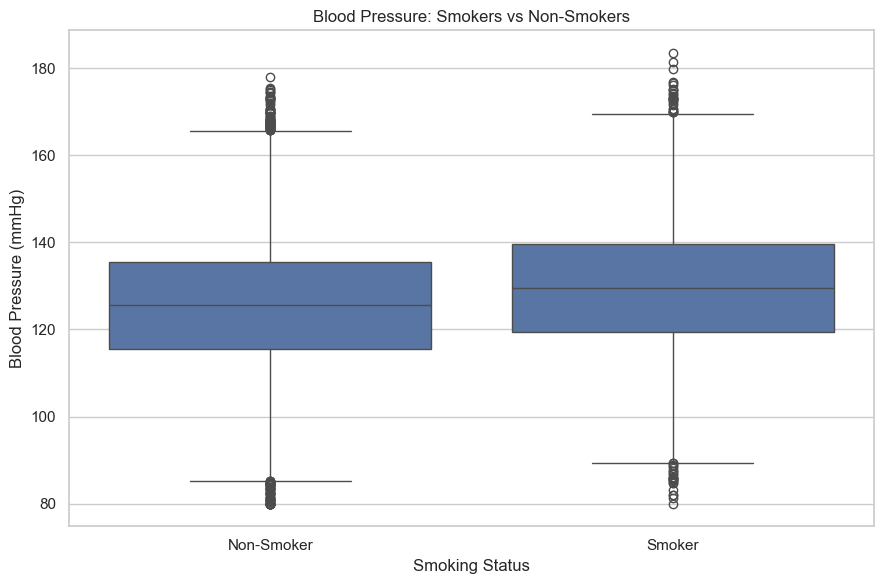

In [37]:
# Compare blood pressure distributions

plot_data = df[
    df["smoking_status"].isin(["Smoker", "Non-Smoker"])
].copy()

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=plot_data,
    x="smoking_status",
    y="blood_pressure"
)

plt.title("Blood Pressure: Smokers vs Non-Smokers")
plt.xlabel("Smoking Status")
plt.ylabel("Blood Pressure (mmHg)")

plt.tight_layout()
plt.show()

## Analysis of Variance (ANOVA)

One-way ANOVA is used to compare the population means of three or more independent groups.

In this project, ANOVA will be used to compare mean blood pressure across five age groups.

**Null Hypothesis (H₀):** All age groups have equal population mean blood pressure.

**Alternative Hypothesis (H₁):** At least one age group's population mean blood pressure differs.

**Significance Level (α):** 0.05

If the p-value is less than 0.05, we reject H₀. Otherwise, we fail to reject H₀.

In [39]:
# STEP 10: One-Way ANOVA
# Compare mean blood pressure across age groups

from scipy import stats

age_group_order = [
    "18-25",
    "26-35",
    "36-45",
    "46-60",
    "60+"
]

groups = [
    df.loc[
        df["age_group"] == group,
        "blood_pressure"
    ].dropna().to_numpy()
    for group in age_group_order
]

# Calculate group means
print("MEAN BLOOD PRESSURE BY AGE GROUP")
print("=" * 50)

for group_name, values in zip(age_group_order, groups):
    print(
        f"{group_name}: "
        f"Mean = {np.mean(values):.2f}, "
        f"Sample Size = {len(values)}"
    )

# Perform one-way ANOVA
f_statistic, p_value = stats.f_oneway(*groups)

alpha = 0.05

# Calculate degrees of freedom
number_of_groups = len(groups)
total_observations = sum(len(group) for group in groups)

df_between = number_of_groups - 1
df_within = total_observations - number_of_groups

# Critical F-value
critical_value = stats.f.ppf(
    1 - alpha,
    df_between,
    df_within
)

print("\nONE-WAY ANOVA RESULTS")
print("=" * 50)

print(f"F-statistic: {f_statistic:.4f}")
print(f"Between-group degrees of freedom: {df_between}")
print(f"Within-group degrees of freedom: {df_within}")
print(f"Critical F-value: {critical_value:.4f}")
print(f"P-value: {p_value:.8f}")

print("\nSTATISTICAL DECISION")
print("=" * 50)

if p_value < alpha:
    print("Reject H0")
    print(
        "There is statistically significant evidence that "
        "mean blood pressure differs across age groups."
    )
else:
    print("Fail to reject H0")
    print(
        "There is insufficient evidence that mean blood pressure "
        "differs across age groups."
    )

MEAN BLOOD PRESSURE BY AGE GROUP
18-25: Mean = 114.77, Sample Size = 5905
26-35: Mean = 118.39, Sample Size = 7380
36-45: Mean = 122.47, Sample Size = 7310
46-60: Mean = 127.06, Sample Size = 11013
60+: Mean = 135.15, Sample Size = 18392

ONE-WAY ANOVA RESULTS
F-statistic: 4346.1999
Between-group degrees of freedom: 4
Within-group degrees of freedom: 49995
Critical F-value: 2.3721
P-value: 0.00000000

STATISTICAL DECISION
Reject H0
There is statistically significant evidence that mean blood pressure differs across age groups.


## Covariance Analysis

Covariance measures how two numerical variables vary together. A positive covariance indicates that the variables tend to move in the same direction, while a negative covariance indicates that they tend to move in opposite directions.

In this project, covariance will be calculated between age, BMI, blood pressure, weight, cholesterol level, and glucose level to examine their joint variation.

In [43]:
# STEP 11: Covariance Analysis

import pandas as pd
import numpy as np

# Select numerical variables
numerical_columns = [
    "age",
    "weight",
    "bmi",
    "blood_pressure",
    "cholesterol_level",
    "glucose_level"
]

# Create a numerical dataset
numerical_data = df[numerical_columns]

# Calculate sample covariance matrix
covariance_matrix = numerical_data.cov()

print("COVARIANCE MATRIX")
print("=" * 70)

display(covariance_matrix.round(3))

COVARIANCE MATRIX


,age,weight,bmi,blood_pressure,cholesterol_level,glucose_level
age,385.903,38.970,13.854,152.294,223.199,175.289
weight,38.970,210.514,50.944,42.939,71.429,70.549
bmi,13.854,50.944,17.944,15.030,25.072,24.900
blood_pressure,152.294,42.939,15.030,216.697,100.192,81.374
cholesterol_level,223.199,71.429,25.072,100.192,938.071,119.343
glucose_level,175.289,70.549,24.900,81.374,119.343,417.029


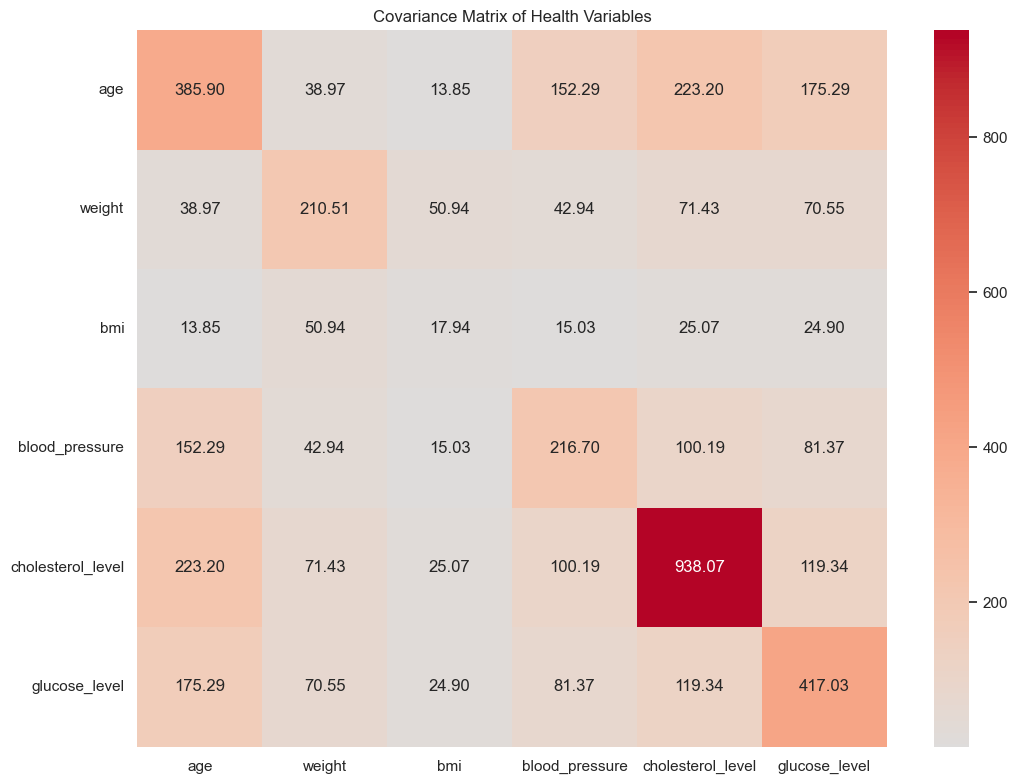

In [44]:
# Visualize covariance matrix

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 8))

sns.heatmap(
    covariance_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Covariance Matrix of Health Variables")
plt.tight_layout()
plt.show()

In [45]:
# STEP 12: Statistical Results Summary

results_summary = pd.DataFrame([
    {
        "Test": "Chi-Square Test",
        "Research Question": "Smoking Status vs Diabetes",
        "Test Statistic": chi2_statistic,
        "Critical Value": critical_value,
        "P-value": p_value
    }
])

display(results_summary)

,Test,Research Question,Test Statistic,Critical Value,P-value
0,Chi-Square Test,Smoking Status vs Diabetes,55.537155,2.37211,0.0


In [46]:
import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import chi2_contingency, pearsonr, ttest_ind, f_oneway

alpha = 0.05
results = []

# 1. CHI-SQUARE TEST: Smoking Status vs Diabetes
chi_table = pd.crosstab(df["smoking_status"], df["diabetes"])
chi_stat, chi_p, chi_dof, expected = chi2_contingency(chi_table)
chi_critical = stats.chi2.ppf(1 - alpha, chi_dof)

results.append({
    "Test": "Chi-Square",
    "Comparison": "Smoking Status vs Diabetes",
    "Statistic": chi_stat,
    "Critical Value": chi_critical,
    "P-Value": chi_p,
    "Decision": "Reject H0" if chi_p < alpha else "Fail to Reject H0"
})

# 2. PEARSON CORRELATION: Age vs BMI
valid_data = df[["age", "bmi"]].dropna()
corr_r, corr_p = pearsonr(valid_data["age"], valid_data["bmi"])

n = len(valid_data)
corr_t_critical = stats.t.ppf(1 - alpha / 2, n - 2)
corr_r_critical = corr_t_critical / np.sqrt(
    corr_t_critical**2 + n - 2
)

results.append({
    "Test": "Pearson Correlation",
    "Comparison": "Age vs BMI",
    "Statistic": corr_r,
    "Critical Value": corr_r_critical,
    "P-Value": corr_p,
    "Decision": "Reject H0" if corr_p < alpha else "Fail to Reject H0"
})

# 3. WELCH'S T-TEST: Blood Pressure by Smoking Status
smoking_categories = df["smoking_status"].dropna().astype(str).unique()
print("Smoking categories in dataset:", smoking_categories)

# Detect a smoker category and a non-smoker/never-smoked category.
smoker_category = next(
    (x for x in smoking_categories
     if "smok" in x.lower()
     and not any(term in x.lower() for term in ["non", "never", "no "])),
    None
)

non_smoker_category = next(
    (x for x in smoking_categories
     if any(term in x.lower() for term in ["non-smok", "non smoker", "never", "no "])),
    None
)

# Also support common Yes/No or Current/Never labels.
if smoker_category is None:
    smoker_category = next(
        (x for x in smoking_categories
         if x.lower() in ["yes", "current", "current smoker"]),
        None
    )

if non_smoker_category is None:
    non_smoker_category = next(
        (x for x in smoking_categories
         if x.lower() in ["no", "never smoked", "never smoker"]),
        None
    )

if smoker_category is not None and non_smoker_category is not None:
    group1 = df.loc[
        df["smoking_status"].astype(str) == smoker_category,
        "blood_pressure"
    ].dropna()

    group2 = df.loc[
        df["smoking_status"].astype(str) == non_smoker_category,
        "blood_pressure"
    ].dropna()

    if len(group1) > 1 and len(group2) > 1:
        t_stat, t_p = ttest_ind(group1, group2, equal_var=False)

        n1, n2 = len(group1), len(group2)
        v1, v2 = group1.var(ddof=1), group2.var(ddof=1)

        welch_df = (v1/n1 + v2/n2)**2 / (
            (v1/n1)**2/(n1-1) + (v2/n2)**2/(n2-1)
        )

        t_critical = stats.t.ppf(1 - alpha/2, welch_df)

        results.append({
            "Test": "Welch's t-Test",
            "Comparison": "Blood Pressure: Smoker vs Non-Smoker",
            "Statistic": t_stat,
            "Critical Value": t_critical,
            "P-Value": t_p,
            "Decision": "Reject H0" if t_p < alpha else "Fail to Reject H0"
        })
    else:
        print("T-test skipped: insufficient records in one or both groups.")
else:
    print("T-test skipped: smoker/non-smoker categories could not be identified.")
    print("Check the smoking categories printed above.")

# 4. ONE-WAY ANOVA: Blood Pressure across Age Groups
age_group_order = ["18-25", "26-35", "36-45", "46-60", "60+"]

bp_groups = [
    df.loc[df["age_group"] == group, "blood_pressure"].dropna().values
    for group in age_group_order
]
bp_groups = [group for group in bp_groups if len(group) > 0]

if len(bp_groups) >= 2:
    f_stat, f_p = f_oneway(*bp_groups)

    total_n = sum(len(group) for group in bp_groups)
    k = len(bp_groups)
    df_between = k - 1
    df_within = total_n - k

    f_critical = stats.f.ppf(1 - alpha, df_between, df_within)

    results.append({
        "Test": "One-Way ANOVA",
        "Comparison": "Blood Pressure across Age Groups",
        "Statistic": f_stat,
        "Critical Value": f_critical,
        "P-Value": f_p,
        "Decision": "Reject H0" if f_p < alpha else "Fail to Reject H0"
    })
else:
    print("ANOVA skipped: insufficient age groups.")

# FINAL RESULTS TABLE
results_df = pd.DataFrame(results)

results_df["Statistic"] = results_df["Statistic"].round(4)
results_df["Critical Value"] = results_df["Critical Value"].round(4)
results_df["P-Value"] = results_df["P-Value"].apply(
    lambda value: f"{value:.6g}"
)
results_df["Significance Level"] = alpha

display(results_df)

Smoking categories in dataset: ['Former Smoker' 'Non-Smoker' 'Smoker']


,Test,Comparison,Statistic,Critical Value,P-Value,Decision,Significance Level
0,Chi-Square,Smoking Status vs Diabetes,55.5372,5.9915,8.71485e-13,Reject H0,0.05
1,Pearson Correlation,Age vs BMI,0.1665,0.0088,1.44757e-307,Reject H0,0.05
2,Welch's t-Test,Blood Pressure: Smoker vs Non-Smoker,9.3383,1.9602,1.14276e-20,Reject H0,0.05
3,One-Way ANOVA,Blood Pressure across Age Groups,4346.1999,2.3721,0,Reject H0,0.05


# Interpretation of Statistical Results

The statistical tests were conducted using a significance level of 0.05.

1. **Chi-Square Test:** This test examines whether smoking status and diabetes status are associated. If the p-value is below 0.05, the null hypothesis is rejected, indicating evidence of an association between the variables.

2. **Pearson Correlation:** This test measures the strength and direction of the linear relationship between age and BMI. A positive correlation indicates that the variables tend to increase together, while a negative correlation indicates that one tends to decrease as the other increases.

3. **Welch's Independent Samples t-Test:** This test compares the average blood pressure of smokers and non-smokers. A p-value below 0.05 provides evidence of a difference between the two group means.

4. **One-Way ANOVA:** This test checks whether mean blood pressure differs across age groups. A p-value below 0.05 indicates that at least one age-group mean differs significantly from the others.

## Conclusion Rule

For each test, the null hypothesis is rejected when the p-value is less than 0.05. Otherwise, the null hypothesis is not rejected.

The final interpretation must be based on the actual calculated p-values and test results. Statistical association does not establish causation.

# Type I and Type II Errors

## Type I Error (False Positive)

A Type I error occurs when we reject the null hypothesis even though it is actually true.

**Example:** A statistical test concludes that smoking status is associated with diabetes when, in reality, no association exists.

**Probability:** Represented by α (alpha). In this project, the significance level is 0.05.

## Type II Error (False Negative)

A Type II error occurs when we fail to reject the null hypothesis even though it is actually false.

**Example:** A statistical test fails to detect an association between smoking status and diabetes even though an association actually exists.

**Probability:** Represented by β (beta).

## Difference Between Type I and Type II Errors

| Feature | Type I Error | Type II Error |
|---|---|---|
| Meaning | Rejecting a true null hypothesis | Failing to reject a false null hypothesis |
| Common term | False Positive | False Negative |
| Symbol | α | β |
| Project example | Incorrectly detecting an association | Failing to detect a real association |

## Importance

Understanding these errors helps us interpret statistical test results carefully. A p-value below 0.05 does not guarantee that a finding is correct, and a p-value above 0.05 does not prove that no relationship exists.

# Final Conclusion

The **Derivable Judgement: A Statistical Decision-Making Model** project applies statistical techniques to a health-related dataset to demonstrate how data can support evidence-based decisions.

The analysis includes descriptive statistics, data visualizations, confidence intervals, hypothesis testing, the Chi-Square test, Pearson correlation, an independent-samples t-test, One-Way ANOVA, covariance, and correlation analysis.

The statistical tests evaluate potential relationships between smoking status and diabetes, the linear relationship between age and BMI, differences in blood pressure between smoking groups, and differences in blood pressure across age groups.

The results are interpreted using a significance level of 0.05. The null hypothesis is rejected when the p-value is below 0.05; otherwise, there is insufficient statistical evidence to reject it.

This project demonstrates how statistical methods can help identify patterns, evaluate hypotheses, and communicate findings systematically. However, statistical relationships do not establish causation. Since the dataset is synthetically generated for educational purposes, the findings should not be treated as medical conclusions or evidence about real patients.

Overall, the project provides practical experience in statistical analysis, hypothesis testing, visualization, and evidence-based decision-making using Python.